# MiHI Data Analysis: Solar Atmospheric Oscillations

## Overview

This notebook focuses on the analysis of a time series of observations acquired with the MiHI instrument. The dataset contains information from the chromospheric H$\alpha$ and photospheric Si I spectral lines, including their corresponding Doppler velocity measurements.

The main goal is to investigate oscillatory motions in the solar atmosphere, with particular emphasis on identifying and characterizing potential magnetohydrodynamic (MHD) wave signatures.

## Objectives

1. **Time–distance analysis:** Construct time–distance diagrams along selected spatial slits to identify possible transverse MHD wave signatures.

2. **Oscillation characterization:** Analyze the detected oscillations to estimate their properties, such as periods, amplitudes, and, where measurable, propagation characteristics.

3. **Wavenumber–frequency analysis:** Construct a $k$–$\omega$ diagram from the photospheric Doppler velocity data to investigate the spatial and temporal frequency distribution of oscillatory power.

In [2]:
import numpy as np
from astropy.io import fits 
import os
import matplotlib.pyplot as plt

fits_file=os.path.join('../data/2018_08_25/cubes/','all_atm_2comp.fits')

with fits.open(fits_file) as hdul:
    atm_data = hdul[0].data      # shape: (N_time, N_param, ny, nx) : (778,33,116,126)
    atm_hdr  = hdul[0].header
    atm_extra = hdul[1].data 
    #hdul.info()
print(atm_hdr)
print(hdul[0].shape)

SIMPLE  =                    T / Written by IDL:  Wed Oct 11 14:13:33 2023      BITPIX  =                  -32 / number of bits per data pixel                  NAXIS   =                    4 / number of data axes                            NAXIS1  =                  126 / Number of positions along axis 1               NAXIS2  =                  116 / Number of positions along axis 2               NAXIS3  =                   33 / Number of positions along axis 3               NAXIS4  =                  778 / Number of positions along axis 4               EXTEND  =                    T / FITS dataset may contain extensions            COMMENT   FITS (Flexible Image Transport System) format is defined in 'AstronomyCOMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H DATE    = '2023-07-07T05:12:37' / file creation date (YYYY-MM-DDThh:mm:ss UT)   CODE    = 'HELIX+  '           / inversion code                                 GITREV  = 'not available'      / GIT rev

In [21]:
import numpy as np
from IPython.display import display, Markdown

dt = np.diff(atm_extra)
print("dt values inside the cube:", np.unique(np.round(dt, 6)))
print("anomalous discontinuities:", np.where(dt > 1)[0])
print("The first anomalous jump is about:", atm_extra[128]-atm_extra[127],
      "while the second one is about:", atm_extra[416]-atm_extra[415])

i = 777

display(Markdown(
    rf'The final time of the cube is **{atm_extra[i]:.2f} s**. '
    rf'Using the nominal cadence of $\Delta t = 0.8\,\mathrm{{s}}$ '
    rf'plus the two jumps: '
    rf'$(775 \times 0.8 + 2 \times 1.6) = {775*0.8+2*1.6:.2f}\,\mathrm{{s}}$'
))

dt values inside the cube: [0.799988 0.799995 0.799999 0.8      0.800001 0.800003 0.800018 0.800049
 1.599998 1.600006]
anomalous discontinuities: [127 415]
The first anomalous jump is about: 1.5999985 while the second one is about: 1.6000061


The final time of the cube is **623.20 s**. Using the nominal cadence of $\Delta t = 0.8\,\mathrm{s}$ plus the two jumps: $(775 \times 0.8 + 2 \times 1.6) = 623.20\,\mathrm{s}$

### Note about the temporal cadence
The temporal cadence of the MiHI data cube is approximately $\Delta t = 0.8$ s, as determined from the time information associated with its first axis. The observations exhibit a nearly uniform cadence, with only two discontinuities: between frames 127–128 and 415–416. At these locations, the time interval increases to approximately 1.6 s, twice the nominal cadence, suggesting a missing temporal sample in each case.

## Open the cube and choose the data of interest (Photospheric VLOS, Cromospheric VLOS, $H_\alpha$ VLOS 

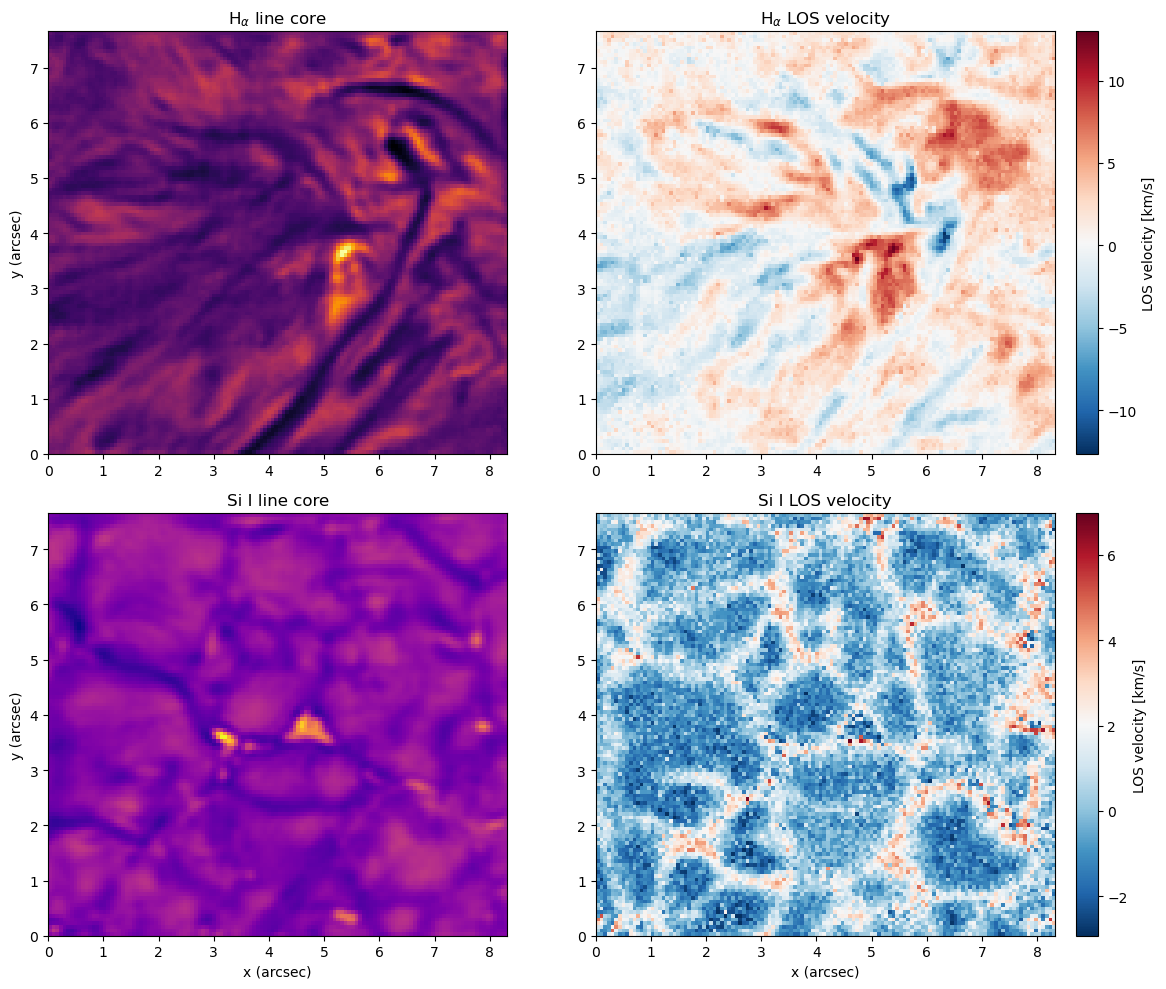

In [23]:
import numpy as np
from astropy.io import fits 
import os
import matplotlib.pyplot as plt

#fits_file='all_atm_2comp.fits'

with fits.open(fits_file) as hdul:
    atm_data = hdul[0].data      # shape: (N_time, N_param, ny, nx)
    atm_hdr  = hdul[0].header
    atm_extra = hdul[1].data  
Q_1, Q_2, Q_3= 32, 13, 0
ha_core   = atm_data[:, Q_1, :, :]  # Hα line core
si_vlos   = atm_data[:, Q_2, :, :]  # Si I LOS velocity
ha_vlos   = atm_data[:, Q_3, :, :]  # Hα LOS velocity
sii_core= atm_data[:,30,:,:]

pixel_scale = 0.066 # arcsec/pix
t = 377 

# =========================================================================
# REFERENCE IMAGES
# =========================================================================

ref1 = np.fliplr(ha_core[t])
ref2 = np.fliplr(ha_vlos[t])
ref3 = np.fliplr(sii_core[t])
ref4 = np.fliplr(si_vlos[t])

# =========================================================================
# SPATIAL EXTENT IN ARCSECONDS
# =========================================================================

ny, nx = ref1.shape

extent_arcsec = [0, nx * pixel_scale, 0, ny * pixel_scale]

# =========================================================================
# 2x2 MOSAIC
# =========================================================================

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# -------------------------------------------------------------------------
# Panel (0,0): H-alpha line core
# -------------------------------------------------------------------------

im0 = axes[0, 0].imshow(
    ref1,
    origin='lower',
    cmap='inferno',
    extent=extent_arcsec
)

axes[0, 0].set_title(r'H$_\alpha$ line core')
axes[0, 0].set_ylabel('y (arcsec)')


# -------------------------------------------------------------------------
# Panel (0,1): H-alpha LOS velocity
# -------------------------------------------------------------------------

im1 = axes[0, 1].imshow(
    ref2,
    origin='lower',
    cmap='RdBu_r',
    extent=extent_arcsec
)

axes[0, 1].set_title(r'H$_\alpha$ LOS velocity')

cbar1 = fig.colorbar(
    im1,
    ax=axes[0, 1],
    fraction=0.046,
    pad=0.04
)

cbar1.set_label('LOS velocity [km/s]')


# -------------------------------------------------------------------------
# Panel (1,0): Si I line core
# -------------------------------------------------------------------------

im2 = axes[1, 0].imshow(
    ref3,
    origin='lower',
    cmap='plasma',
    extent=extent_arcsec
)

axes[1, 0].set_title('Si I line core')
axes[1, 0].set_xlabel('x (arcsec)')
axes[1, 0].set_ylabel('y (arcsec)')


# -------------------------------------------------------------------------
# Panel (1,1): Si I LOS velocity
# -------------------------------------------------------------------------

im3 = axes[1, 1].imshow(
    ref4,
    origin='lower',
    cmap='RdBu_r',
    extent=extent_arcsec
)

axes[1, 1].set_title('Si I LOS velocity')
axes[1, 1].set_xlabel('x (arcsec)')

cbar3 = fig.colorbar(
    im3,
    ax=axes[1, 1],
    fraction=0.046,
    pad=0.04
)

cbar3.set_label('LOS velocity [km/s]')


# =========================================================================
# FORMATTING
# =========================================================================

for ax in axes.flat:
    ax.set_aspect('equal')

plt.tight_layout()
plt.show()

dt:  0.79999924
pixel scale:  47.85 km/pix


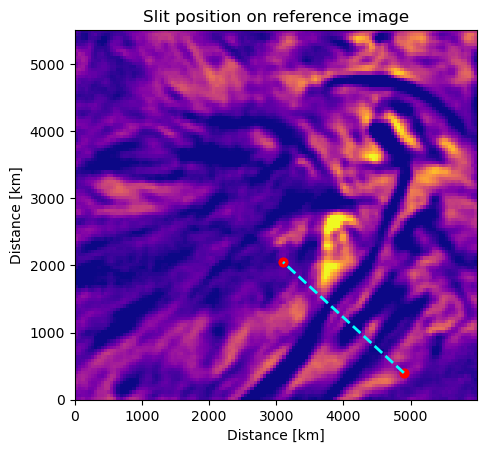

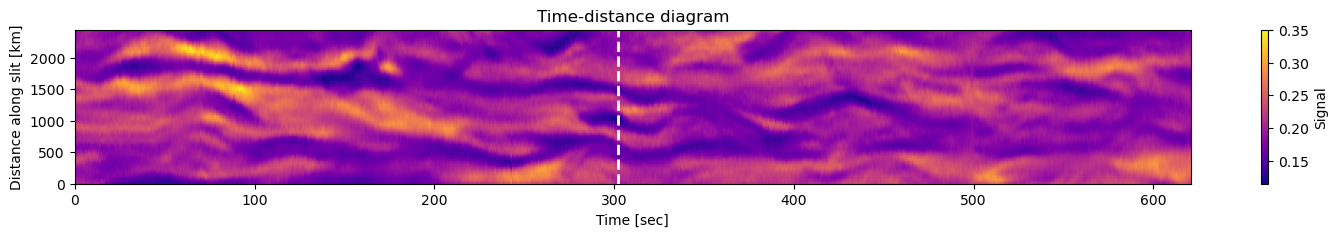

<Figure size 800x800 with 0 Axes>

<Figure size 800x800 with 0 Axes>

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

# --- Parámetros del slit ---
x0, y0 = 4900, 400
x1, y1 = 3100, 2050 #original es y=2050
npoints = 100

# --- Delta of time ---
dt = np.median(np.diff(atm_extra))   # o dt = 0.8

Nt=777
Ny, Nx = ref2.shape
pixel_size_km=0.066*725 # arcsec/pix km/arcsec . This value is a reference value, for the exact value please use Sunpy 
print('dt: ', dt)
print('pixel scale: ', pixel_size_km, 'km/pix')
x = np.arange(nx) * pixel_size_km
y = np.arange(ny) * pixel_size_km

# --- Eje espacial del slit en coordenadas físicas, kilometros---
xs_km = np.linspace(x0, x1, npoints)
ys_km = np.linspace(y0, y1, npoints)
#-- Eje espacial del slit en coordenadas de píxeles de imagen -- 
xs_pix = xs_km / pixel_size_km
ys_pix = ys_km / pixel_size_km

stack = np.zeros((Nt, npoints)) # Initialize a zero-filled matrix (Nt × npoints) to store the spatial slit profile at each time step.
ha_core_flip = np.flip(ha_core, axis=2) # Same orientation for all the times
# --- Recorrer todos los tiempos ---
for t in range(Nt):
    image = ha_core_flip[t, :, :]
    slit_values = map_coordinates( # Sample the image along the slit using bilinear interpolation at the specified pixel coordinates.
        image,
        [ys_pix, xs_pix],
        order=1,
        mode='nearest'
    )
    stack[t, :] = slit_values

# --- Ejes del diagrama tiempo-distancia ---
time_axis = np.arange(Nt) * dt
slit_length_km = np.sqrt((x1 - x0)**2 + (y1 - y0)**2)
distance_axis = np.linspace(0, slit_length_km, npoints)

#---slit position -----
plt.imshow(
    ref1,
    origin='lower',
    extent=[x.min(), x.max(), y.min(), y.max()],
    vmin=np.percentile(ref1, 10),
    vmax=np.percentile(ref1, 99.8),
    cmap='plasma'
)

plt.plot([x0, x1], [y0, y1], color='cyan', linestyle='--', linewidth=2)
plt.scatter([x0, x1], [y0, y1], color='red', s=40)

plt.xlabel('Distance [km]')
plt.ylabel('Distance [km]')
plt.title('Slit position on reference image')
plt.show()

# --- Gráfica final ---
plt.figure(figsize=(18, 2))
plt.imshow(
    stack.T,
    origin='lower',
    aspect='auto',
    extent=[
        time_axis.min(), time_axis.max(),
        distance_axis.min(), distance_axis.max()
    ],
    cmap='plasma'
)
time_mark = atm_extra[377]   # o time_axis[415] si construiste time_axis
plt.axvline(time_mark, color='white', linestyle='--', linewidth=2)
plt.xlabel('Time [sec]')
plt.ylabel('Distance along slit [km]')
plt.title('Time-distance diagram')
plt.colorbar(label='Signal')
plt.show()
plt.figure(figsize=(8, 8))



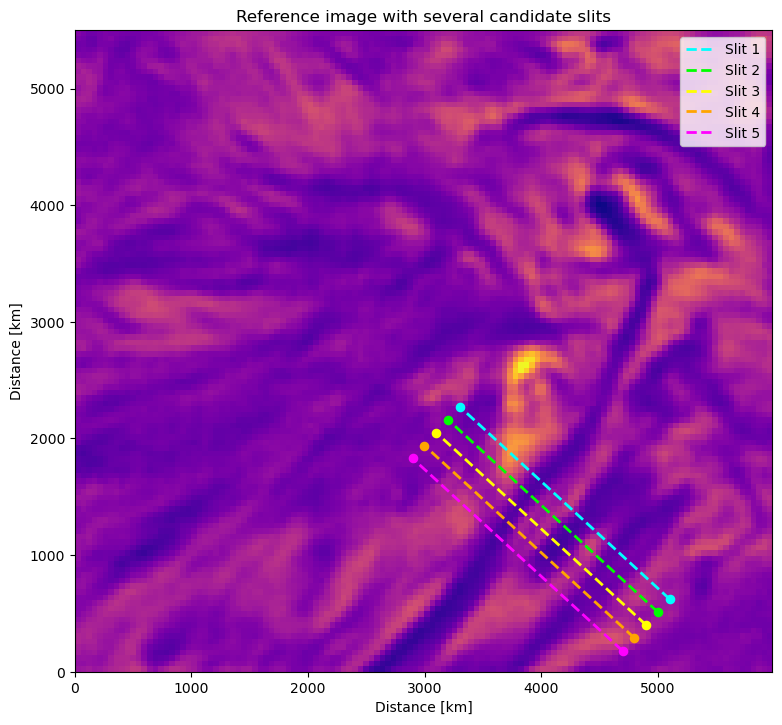

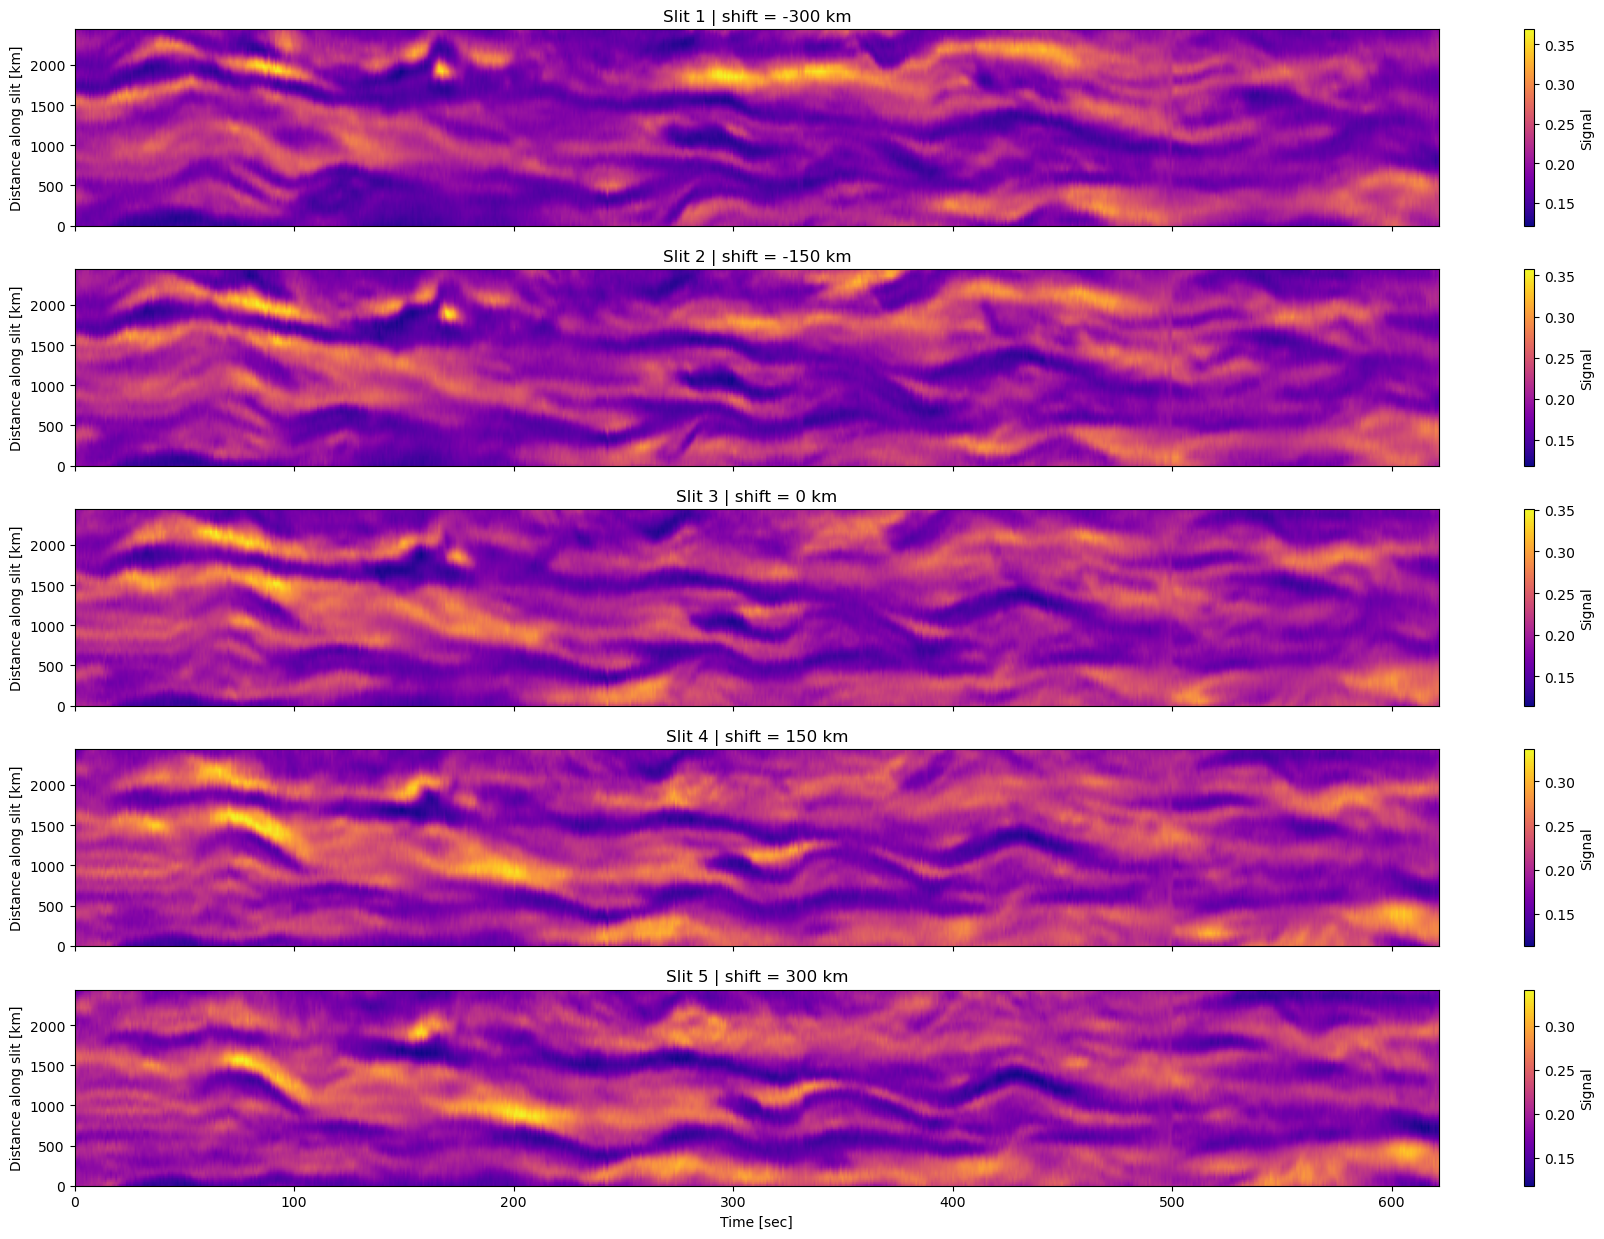

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

# -----------------------------
# Slit base
# -----------------------------
x0, y0 = 4900, 400
x1, y1 = 3100, 2050
npoints = 100

# -----------------------------
# Parámetros
# -----------------------------
dt = np.median(np.diff(atm_extra))   # o dt = 0.8 si ya lo confirmaste
Nt, Ny, Nx = ha_core.shape

# -----------------------------
# Funciones auxiliares
# -----------------------------
def make_parallel_slit(x0, y0, x1, y1, shift_km):
    dx = x1 - x0
    dy = y1 - y0
    L = np.hypot(dx, dy)
    nx = -dy / L
    ny =  dx / L
    return (
        x0 + shift_km * nx,
        y0 + shift_km * ny,
        x1 + shift_km * nx,
        y1 + shift_km * ny
    )

def time_distance_for_slit(image_stack, x0, y0, x1, y1, npoints, pixel_size_km, dt):
    xs_km = np.linspace(x0, x1, npoints)
    ys_km = np.linspace(y0, y1, npoints)

    xs_pix = xs_km / pixel_size_km
    ys_pix = ys_km / pixel_size_km

    Nt = image_stack.shape[0]
    stack = np.zeros((Nt, npoints))

    for t in range(Nt):
        image = image_stack[t, :, :]
        slit_values = map_coordinates(
            image,
            [ys_pix, xs_pix],
            order=1,
            mode='nearest'
        )
        stack[t, :] = slit_values

    time_axis = np.arange(Nt) * dt
    slit_length_km = np.hypot(x1 - x0, y1 - y0)
    distance_axis = np.linspace(0, slit_length_km, npoints)

    return stack, time_axis, distance_axis

# -----------------------------
# Definir varios slits parecidos
# -----------------------------
shift_values = [-300, -150, 0, 150, 300]  # km, ajusta a gusto

slits = []
for s in shift_values:
    sx0, sy0, sx1, sy1 = make_parallel_slit(x0, y0, x1, y1, s)
    slits.append((sx0, sy0, sx1, sy1))

# -----------------------------
# Figura 1: referencia + varios slits
# -----------------------------
plt.figure(figsize=(9, 9))

plt.imshow(
    ref1,
    origin='lower',
    extent=[x.min(), x.max(), y.min(), y.max()],
    cmap='plasma'
)

colors = ['cyan', 'lime', 'yellow', 'orange', 'magenta']

for i, (sx0, sy0, sx1, sy1) in enumerate(slits):
    c = colors[i % len(colors)]
    plt.plot([sx0, sx1], [sy0, sy1], color=c, linestyle='--', linewidth=2, label=f'Slit {i+1}')
    plt.scatter([sx0, sx1], [sy0, sy1], color=c, s=35)

plt.xlabel('Distance [km]')
plt.ylabel('Distance [km]')
plt.title('Reference image with several candidate slits')
plt.legend()
plt.show()

# -----------------------------
# Time-distance plots
# -----------------------------
fig, axes = plt.subplots(len(slits), 1, figsize=(18, 2.5 * len(slits)), sharex=True)

if len(slits) == 1:
    axes = [axes]

for i, (sx0, sy0, sx1, sy1) in enumerate(slits):
    stack, time_axis, distance_axis = time_distance_for_slit(
        ha_core_flip, sx0, sy0, sx1, sy1, npoints, pixel_size_km, dt
    )

    ax = axes[i]
    im = ax.imshow(
        stack.T,
        origin='lower',
        aspect='auto',
        extent=[
            time_axis.min(), time_axis.max(),
            distance_axis.min(), distance_axis.max()
        ],
        cmap='plasma'
    )
    ax.set_ylabel('Distance along slit [km]')
    ax.set_title(f'Slit {i+1} | shift = {shift_values[i]} km')
    fig.colorbar(im, ax=ax, label='Signal')

axes[-1].set_xlabel('Time [sec]')
plt.tight_layout()
plt.show()

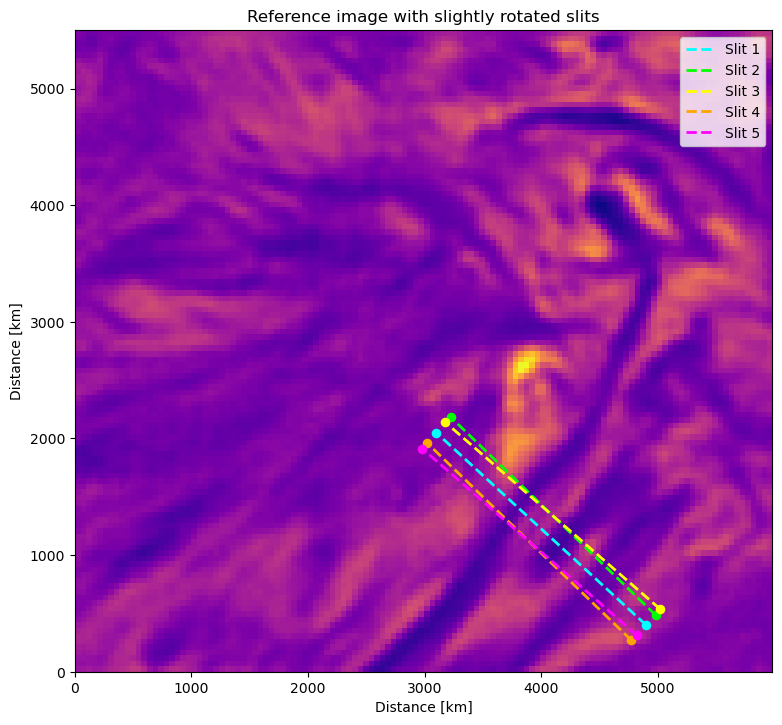

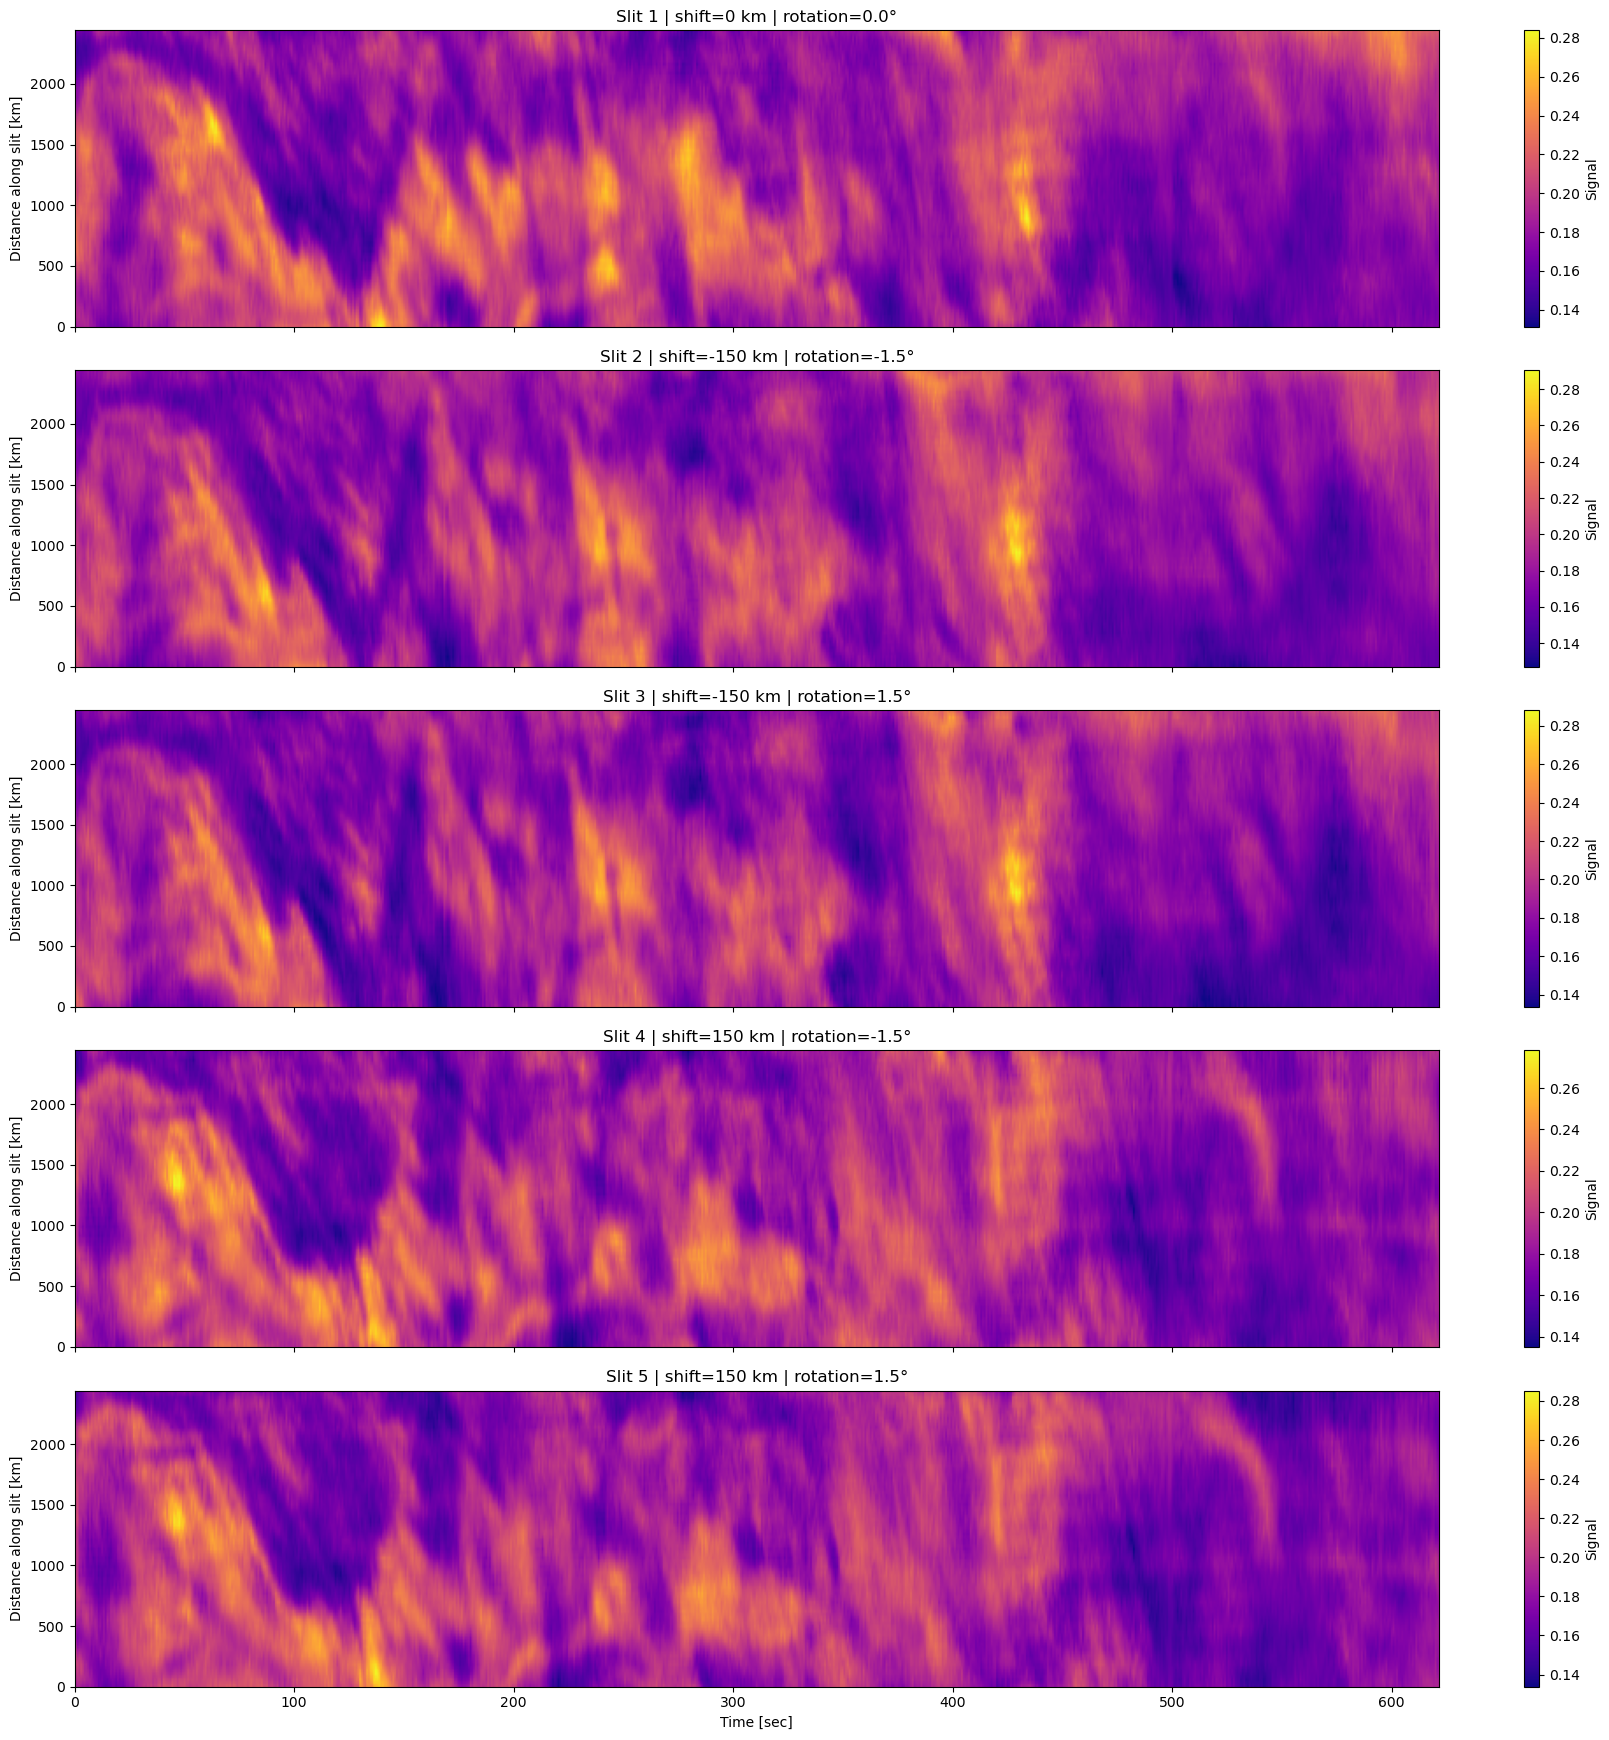

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

# -----------------------------
# Slit base
# -----------------------------
x0, y0 = 4900, 400
x1, y1 = 3100, 2050
npoints = 100

Nt, Ny, Nx = param2.shape
dt = np.median(np.diff(atm_extra))   # o dt = 0.8 si ya lo confirmaste

# -----------------------------
# Funciones auxiliares
# -----------------------------
def rotate_point(px, py, cx, cy, angle_rad):
    dx = px - cx
    dy = py - cy
    ca = np.cos(angle_rad)
    sa = np.sin(angle_rad)
    xr = cx + dx * ca - dy * sa
    yr = cy + dx * sa + dy * ca
    return xr, yr

def make_slit_variant(x0, y0, x1, y1, shift_km=0.0, angle_deg=0.0):
    dx = x1 - x0
    dy = y1 - y0
    L = np.hypot(dx, dy)
    xm = 0.5 * (x0 + x1)
    ym = 0.5 * (y0 + y1)

    # vector normal para desplazar perpendicularmente
    nx = -dy / L
    ny =  dx / L

    # desplazamiento lateral
    x0s = x0 + shift_km * nx
    y0s = y0 + shift_km * ny
    x1s = x1 + shift_km * nx
    y1s = y1 + shift_km * ny

    # rotación suave alrededor del punto medio
    ang = np.deg2rad(angle_deg)
    x0r, y0r = rotate_point(x0s, y0s, xm, ym, ang)
    x1r, y1r = rotate_point(x1s, y1s, xm, ym, ang)

    return x0r, y0r, x1r, y1r

def time_distance_for_slit(cube, x0, y0, x1, y1, npoints, pixel_size_km, dt):
    xs_km = np.linspace(x0, x1, npoints)
    ys_km = np.linspace(y0, y1, npoints)

    xs_pix = xs_km / pixel_size_km
    ys_pix = ys_km / pixel_size_km

    Nt = cube.shape[0]
    stack = np.zeros((Nt, npoints))

    for t in range(Nt):
        image = cube[t, :, :]
        slit_values = map_coordinates(image, [ys_pix, xs_pix], order=1, mode='nearest')
        stack[t, :] = slit_values

    time_axis = np.arange(Nt) * dt
    slit_length_km = np.hypot(x1 - x0, y1 - y0)
    distance_axis = np.linspace(0, slit_length_km, npoints)

    return stack, time_axis, distance_axis

# -----------------------------
# Variantes cercanas al slit base
# -----------------------------
variants = [
    (0,   0.0),
    (-150, -1.5),
    (-150,  1.5),
    (150,  -1.5),
    (150,   1.5),
]

slits = [make_slit_variant(x0, y0, x1, y1, shift_km=s, angle_deg=a) for s, a in variants]

# -----------------------------
# Figura: referencia con slits
# -----------------------------
plt.figure(figsize=(9, 9))
plt.imshow(
    ref1,
    origin='lower',
    extent=[x.min(), x.max(), y.min(), y.max()],
    cmap='plasma'
)

colors = ['cyan', 'lime', 'yellow', 'orange', 'magenta']

for i, (sx0, sy0, sx1, sy1) in enumerate(slits):
    c = colors[i % len(colors)]
    plt.plot([sx0, sx1], [sy0, sy1], color=c, linestyle='--', linewidth=2, label=f'Slit {i+1}')
    plt.scatter([sx0, sx1], [sy0, sy1], color=c, s=35)

plt.xlabel('Distance [km]')
plt.ylabel('Distance [km]')
plt.title('Reference image with slightly rotated slits')
plt.legend()
plt.show()

# -----------------------------
# Time-distance plots
# -----------------------------
fig, axes = plt.subplots(len(slits), 1, figsize=(18, 3.5 * len(slits)), sharex=True)

if len(slits) == 1:
    axes = [axes]

for i, (sx0, sy0, sx1, sy1) in enumerate(slits):
    stack, time_axis, distance_axis = time_distance_for_slit(
        param2, sx0, sy0, sx1, sy1, npoints, pixel_size_km, dt
    )

    ax = axes[i]
    im = ax.imshow(
        stack.T,
        origin='lower',
        aspect='auto',
        extent=[
            time_axis.min(), time_axis.max(),
            distance_axis.min(), distance_axis.max()
        ],
        cmap='plasma'
    )
    ax.set_ylabel('Distance along slit [km]')
    ax.set_title(f'Slit {i+1} | shift={variants[i][0]} km | rotation={variants[i][1]}°')
    fig.colorbar(im, ax=ax, label='Signal')

axes[-1].set_xlabel('Time [sec]')
plt.tight_layout()
plt.show()

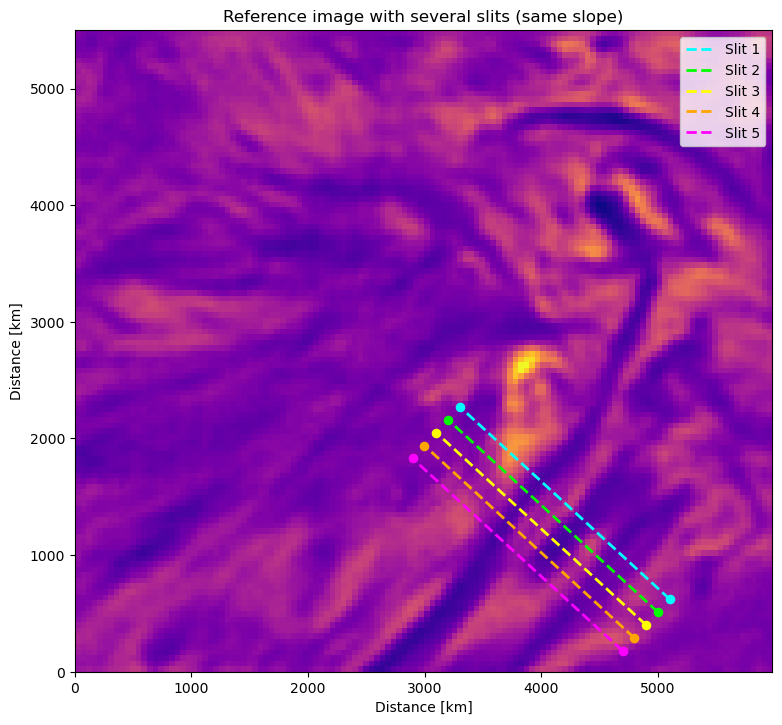

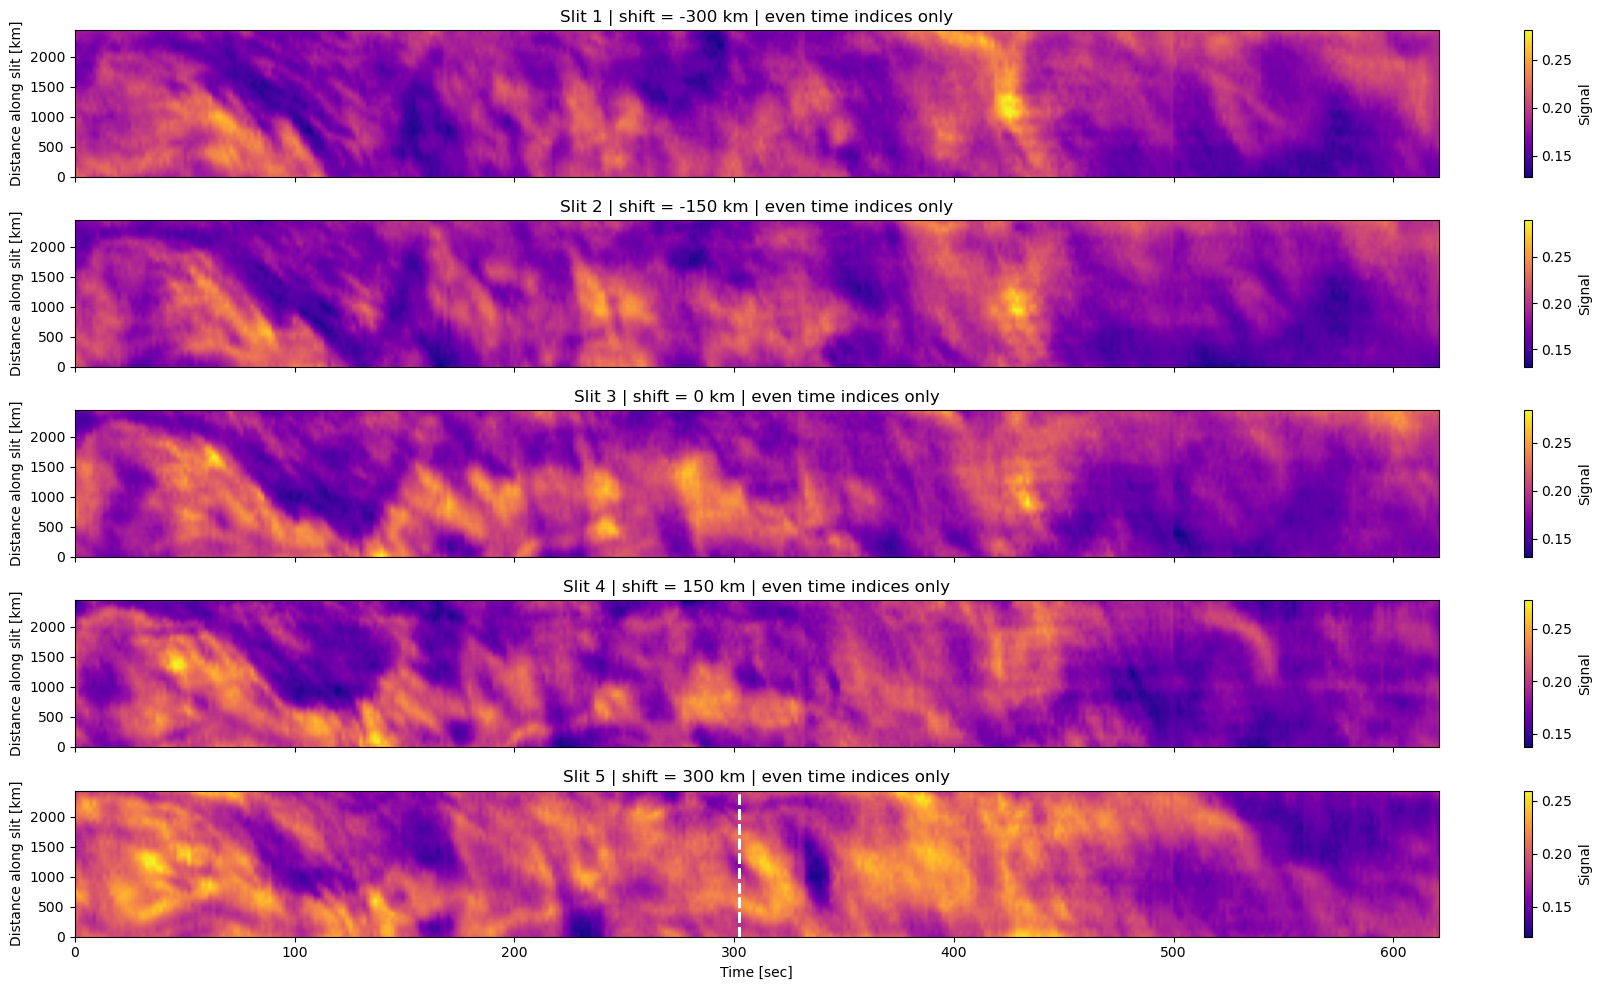

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

# -----------------------------
# Slit base
# -----------------------------
x0, y0 = 4900, 400
x1, y1 = 3100, 2050
npoints = 100

Nt, Ny, Nx = param2.shape
dt = np.median(np.diff(atm_extra))   # or dt = 0.8 if already confirmed

# Use only even time indices
time_idx = np.arange(0, Nt, 2)
Nt2 = len(time_idx)

# -----------------------------
# Functions
# -----------------------------
def rotate_point(px, py, cx, cy, angle_rad):
    dx = px - cx
    dy = py - cy
    ca = np.cos(angle_rad)
    sa = np.sin(angle_rad)
    xr = cx + dx * ca - dy * sa
    yr = cy + dx * sa + dy * ca
    return xr, yr

def make_slit_variant(x0, y0, x1, y1, shift_km=0.0, angle_deg=0.0):
    dx = x1 - x0
    dy = y1 - y0
    L = np.hypot(dx, dy)
    xm = 0.5 * (x0 + x1)
    ym = 0.5 * (y0 + y1)

    nx = -dy / L
    ny =  dx / L

    x0s = x0 + shift_km * nx
    y0s = y0 + shift_km * ny
    x1s = x1 + shift_km * nx
    y1s = y1 + shift_km * ny

    ang = np.deg2rad(angle_deg)
    x0r, y0r = rotate_point(x0s, y0s, xm, ym, ang)
    x1r, y1r = rotate_point(x1s, y1s, xm, ym, ang)

    return x0r, y0r, x1r, y1r

def time_distance_for_slit_even(cube, x0, y0, x1, y1, npoints, pixel_size_km, dt, time_idx):
    xs_km = np.linspace(x0, x1, npoints)
    ys_km = np.linspace(y0, y1, npoints)

    xs_pix = xs_km / pixel_size_km
    ys_pix = ys_km / pixel_size_km

    stack = np.zeros((len(time_idx), npoints))

    for j, t in enumerate(time_idx):
        image = cube[t, :, :]
        slit_values = map_coordinates(image, [ys_pix, xs_pix], order=1, mode='nearest')
        stack[j, :] = slit_values

    time_axis = time_idx * dt
    slit_length_km = np.hypot(x1 - x0, y1 - y0)
    distance_axis = np.linspace(0, slit_length_km, npoints)

    return stack, time_axis, distance_axis

# -----------------------------
# Variants with same slope
# -----------------------------
shift_values = [-300, -150, 0, 150, 300]
slits = [make_slit_variant(x0, y0, x1, y1, shift_km=s, angle_deg=0.0) for s in shift_values]

# -----------------------------
# Figure 1: reference with all slits
# -----------------------------
plt.figure(figsize=(9, 9))
plt.imshow(
    ref1,
    origin='lower',
    extent=[x.min(), x.max(), y.min(), y.max()],
    cmap='plasma'
)

colors = ['cyan', 'lime', 'yellow', 'orange', 'magenta']

for i, (sx0, sy0, sx1, sy1) in enumerate(slits):
    c = colors[i % len(colors)]
    plt.plot([sx0, sx1], [sy0, sy1], color=c, linestyle='--', linewidth=2, label=f'Slit {i+1}')
    plt.scatter([sx0, sx1], [sy0, sy1], color=c, s=35)


plt.xlabel('Distance [km]')
plt.ylabel('Distance [km]')
plt.title('Reference image with several slits (same slope)')
plt.legend()
plt.show()

# -----------------------------
# Time-distance plots using only even time frames
# -----------------------------
fig, axes = plt.subplots(len(slits), 1, figsize=(18, 2 * len(slits)), sharex=True)

if len(slits) == 1:
    axes = [axes]

for i, (sx0, sy0, sx1, sy1) in enumerate(slits):
    stack, time_axis, distance_axis = time_distance_for_slit_even(
        param2, sx0, sy0, sx1, sy1, npoints, pixel_size_km, dt, time_idx
    )

    ax = axes[i]
    im = ax.imshow(
        stack.T,
        origin='lower',
        aspect='auto',
        extent=[
            time_axis.min(), time_axis.max(),
            distance_axis.min(), distance_axis.max()
        ],
        cmap='plasma'
    )
    ax.set_ylabel('Distance along slit [km]')
    ax.set_title(f'Slit {i+1} | shift = {shift_values[i]} km | even time indices only')
    fig.colorbar(im, ax=ax, label='Signal')
    time_mark = atm_extra[377]   # o time_axis[415] si construiste time_axis
    plt.axvline(time_mark, color='white', linestyle='--', linewidth=2)

axes[-1].set_xlabel('Time [sec]')
plt.tight_layout()
plt.show()

In [32]:
reference_time=atm_extra[415]
print(reference_time, t )

332.8 776


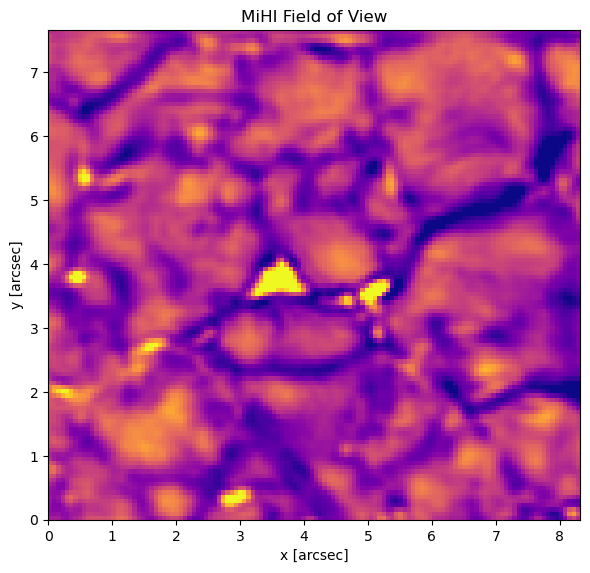

In [52]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 6))

im = ax.imshow(
    sii_core[t],
    origin='lower',
    cmap='plasma',
    vmin=np.nanpercentile(sii_core[t], 1),
    vmax=np.nanpercentile(sii_core[t], 99.5),
    extent=extent_arcsec
)

ax.set_title('MiHI Field of View')
ax.set_xlabel('x [arcsec]')
ax.set_ylabel('y [arcsec]')

# Mantener proporción cuadrada
ax.set_aspect('equal')

# Opcional: si quieres que tenga un zoom equivalente visualmente
# ax.set_xlim(xmin, xmax)
# ax.set_ylim(ymin, ymax)

fig.tight_layout()

fig.savefig(
    'Photospheric_MiHI1.png',
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

In [13]:
# ESCALAS Y RESOLUCIONES DE LAS MEDICIONES 

arcsec_to_km=725 
dy=dx=pixel_scale*arcsec_to_km #Escala espacial
dt=1.3 #Resolución temporal
T=ha_vlos.shape[0]*dt #Muestra temporal
dnu=1/T
print(T/60)
print('Resolución de k: ', 1/dx)

16.85666666666667
Resolución de k:  0.02089864158829676


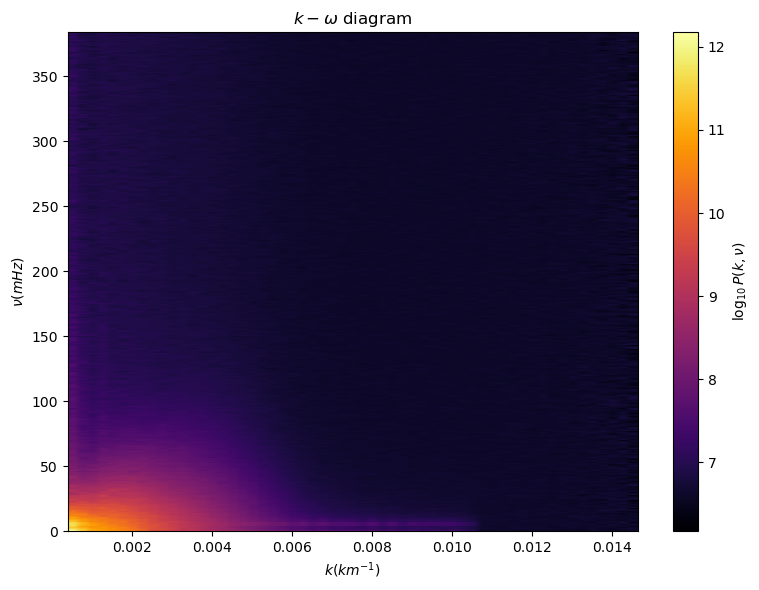

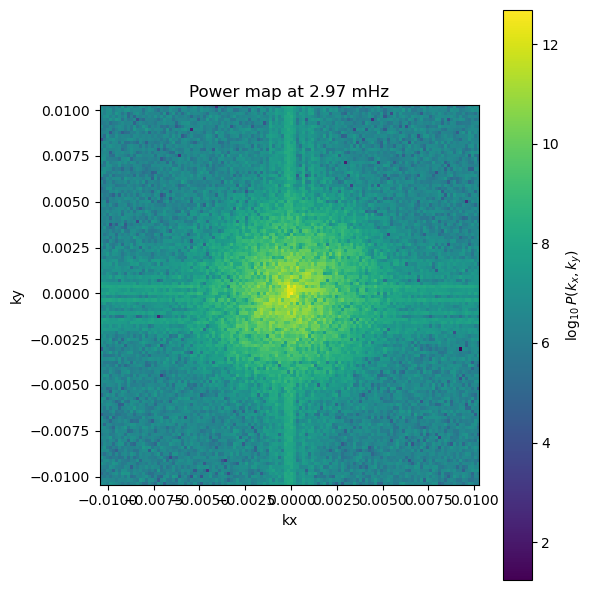

In [12]:
import numpy as np

nt, ny, nx = ha_vlos.shape
#ha_vlos=si_vlos
# temporañ FFT 
fft_t = np.fft.fft(ha_vlos, axis=0)          # shape: (nt, ny, nx)

# Frecuencias correspondientes (Hz)
freq = np.fft.fftfreq(nt, d=dt)           # shape: (nt,)

# Si solo quieres frecuencias positivas:
pos = freq >= 0
fft_t = fft_t[pos, :, :]                  # shape: (nfreq, ny, nx)
freq = freq[pos]                          # shape: (nfreq,)
nfreq = len(freq)
# FFT 2D en (y, x) para cada frecuencia
fft_k = np.fft.fft2(fft_t, axes=(1, 2))     # shape: (nfreq, ny, nx)

# Shift opcional para centrar k=0 en el centro de la imagen
fft_k = np.fft.fftshift(fft_k, axes=(1, 2))

power_cube = np.abs(fft_k)**2     

ky = np.fft.fftfreq(ny, d=dy)
kx = np.fft.fftfreq(nx, d=dx)

ky = np.fft.fftshift(ky)
kx = np.fft.fftshift(kx)

# Malla de kx, ky si la necesitas
KX, KY = np.meshgrid(kx, ky)
K = np.sqrt(KX**2 + KY**2)  # módulo k

# ------------------------------------------------------------
# 5) CONSTRUIR ANILLOS RADIALES EN k
#    (misma idea que READ_complex_datacube.ipynb)
# ------------------------------------------------------------
# Número de bins radiales
nbins = min(nx, ny) // 2

k_min = 0.0
k_max = np.nanmax(K)

k_edges = np.linspace(k_min, k_max, nbins + 1)
k_centers = 0.5 * (k_edges[:-1] + k_edges[1:])

# Asignar cada pixel del plano (ky, kx) a un anillo
k_index = np.digitize(K.ravel(), k_edges) - 1
valid = (k_index >= 0) & (k_index < nbins)

# Número de píxeles por anillo
counts = np.bincount(k_index[valid], minlength=nbins).astype(float)

# Evitar divisiones por cero
counts[counts == 0] = np.nan

# ------------------------------------------------------------
# 6) PROMEDIO AZIMUTAL PARA CADA FRECUENCIA
#    Salida final: omega_k con shape (nfreq, nbins)
# ------------------------------------------------------------
omega_k = np.full((nfreq, nbins), np.nan, dtype=np.float64)

for i in range(nfreq):
    img = power_cube[i].ravel()

    sums = np.bincount(
        k_index[valid],
        weights=img[valid],
        minlength=nbins
    ).astype(float)

    omega_k[i, :] = sums / counts

# ------------------------------------------------------------
# 7) OPCIONAL: RECORTE DE RANGO ÚTIL
# ------------------------------------------------------------
# Muchas veces el primer bin k=0 y frecuencias muy bajas dominan.
# Puedes recortar visualmente para ver mejor las trompetas.
#
# Ejemplo: entre 1 mHz y 10 mHz
freq_mHz = freq * 1e3
fmask = (freq_mHz >= 0) & (freq_mHz <= 1/dt*1e3)

# También puedes omitir los primeros bins de k si el centro satura mucho
k_start = 1

omega_k_plot = omega_k[fmask, k_start:]
freq_plot = freq_mHz[fmask]
k_plot = k_centers[k_start:]

# Escala logarítmica para visualizar mejor
plot_data = np.log10(omega_k_plot + 1e-20)

# ------------------------------------------------------------
# 8) GRAFICAR DIAGRAMA k-omega (trompetas)
# ------------------------------------------------------------
plt.figure(figsize=(8, 6))

extent = [
    k_plot.min(), k_plot.max(),
    freq_plot.min(), freq_plot.max()
]

plt.imshow(
    plot_data,
    origin='lower',
    aspect='auto',
    extent=extent,
    cmap='inferno'
)

plt.xlabel(r"$k(km^{-1})$")
plt.ylabel(r"$\nu (mHz)$")
plt.title(r"$k-\omega$ diagram")
plt.colorbar(label=r'$\log_{10} P(k,\nu)$')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9) INSPECCIÓN EXTRA: CORTE 2D EN UNA FRECUENCIA
# ------------------------------------------------------------
# Esto te permite ver un plano (kx,ky) para una frecuencia específica
# y comprobar visualmente los anillos.
#
# Por ejemplo, frecuencia más cercana a 3 mHz:
target_mHz = 3.0
idx_f = np.argmin(np.abs(freq_mHz - target_mHz))

slice2d = power_cube[idx_f]

plt.figure(figsize=(6, 6))
plt.imshow(
    np.log10(slice2d + 1e-20),
    origin='lower',
    extent=[kx.min(), kx.max(), ky.min(), ky.max()],
    cmap='viridis'
)
plt.xlabel("kx")
plt.ylabel("ky")
plt.title(f"Power map at {freq_mHz[idx_f]:.2f} mHz")
plt.colorbar(label=r'$\log_{10} P(k_x,k_y)$')
plt.tight_layout()
plt.show()